### 📘 **Oct2Py Data Reading and Plotting Demo**

In [1]:
from oct2py import Oct2Py
import matplotlib.pyplot as plt
import time
import csv
import numpy as np

### 🚀 **Initialize Oct2Py Session**

In [5]:
#USE: setx OCTAVE_EXECUTABLE "C:\Program Files\GNU Octave\Octave-10.2.0\mingw64\bin\octave-cli.exe" (or appropriate path) to set Octave path
oc = Oct2Py()
oc.addpath(oc.genpath(r'.\dist'));

### ⏱️ **Read File Info**

In [20]:
oc.addpath('../DynaportCompany_Codes_new/source')

tic = time.perf_counter()
info = oc.feval(
    'OMX_readFile',
    '../Data/OMX_Files/Alex_DATA.OMX',
    1, #info = 1
    nout=1,
    struct_to_dict=False
)
toc = time.perf_counter()
print(f"Read info in {toc - tic:0.4f} seconds")

Read info in 7.4703 seconds


### 📥 **Read ACC Data**

In [21]:
tic = time.perf_counter()
data = oc.feval(
    'OMX_readFile',
    '../Data/OMX_Files/Alex_DATA.OMX',
    0,                        # info
    info.packetInfo,         # packetInfo
    -1,                      # startTime
    -1,                      # stopTime
    0,                       # verbose
    0,                       # useC
    [1, 1, 0],               # modality
    1,                       # step
    nout=1,
    struct_to_dict=False
)
toc = time.perf_counter()
print(f"Read data in {toc - tic:0.4f} seconds")

data = [](0x0)
Read data in 4.5226 seconds


### 💾 **Write ACC Data to CSV**

In [23]:
with open('../Data/CSV_Files_Raw/Alex_DATA_DirectConversion.csv', 'w', newline='') as f:
    writer = csv.writer(f, delimiter=',')

    #column names
    writer.writerow(['Time', 'Ax', 'Ay', 'Az'])

    #writing data
    for row in data['ACC']:
        writer.writerow(row)

### 📊 **Plot the ACC Data**

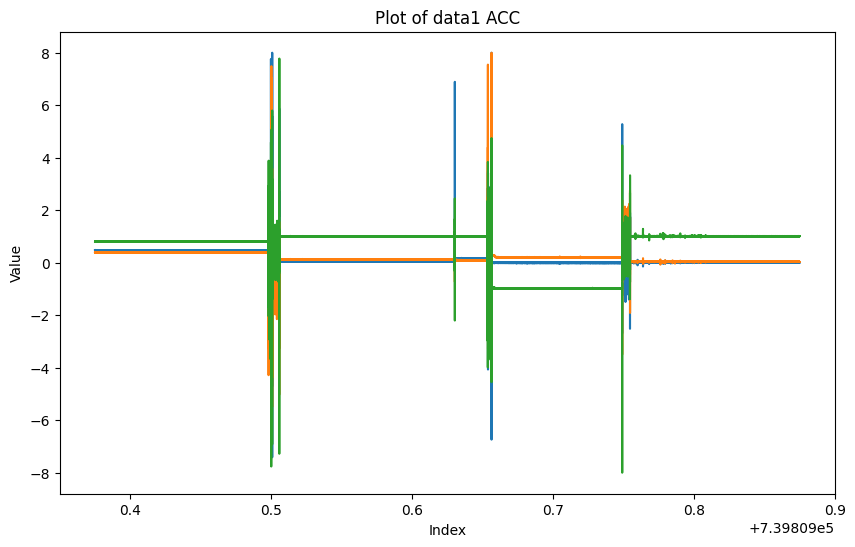

In [24]:
x = data['ACC'][:, 0]
y_columns = data['ACC'][:, 1:4]

plt.figure(figsize=(10, 6))
plt.plot(x, y_columns)
plt.title('Plot of data1 ACC')
plt.xlabel('Index')
plt.ylabel('Value')
plt.show()